# Unit 8 – Gradient descent and the cost function
Companion to Mayo (2017), *Explained: Updating Weights with Gradient Descent & Backpropagation*.

Model: ŷ = m·x + c. Cost: J(m, c) = (1/N) Σ (yᵢ − ŷᵢ)². Gradients: ∂J/∂m = −(2/N) Σ xᵢ(yᵢ − ŷᵢ), ∂J/∂c = −(2/N) Σ (yᵢ − ŷᵢ). Each iteration moves the parameters a step of size `learning_rate` **against** the gradient.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
np.random.seed(42)

Gradient descent : m=3.912, c=7.405, final cost=3.227
Closed-form OLS  : m=3.908, c=7.430


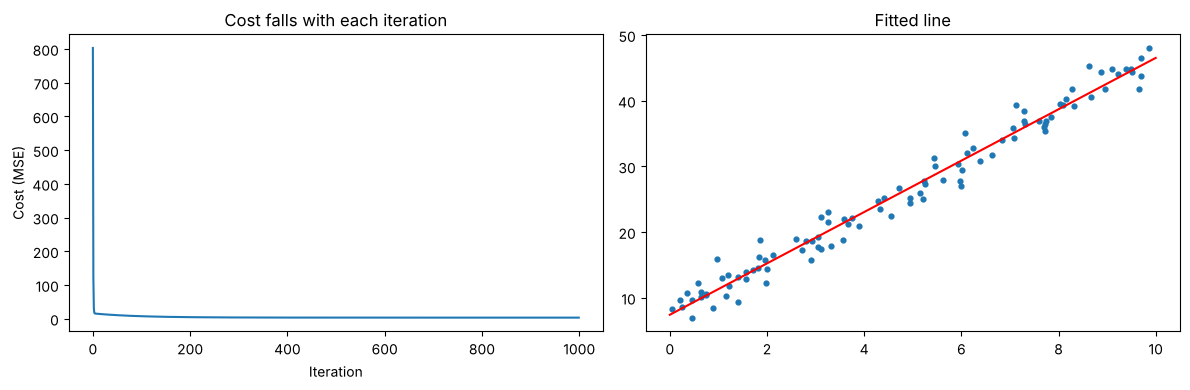

In [2]:
rng = np.random.RandomState(42)
x = rng.uniform(0, 10, 100)
y = 4 * x + 7 + rng.normal(0, 2, 100)           # true m=4, c=7

def gradient_descent(x, y, iterations=1000, learning_rate=0.01):
    m = c = 0.0; n = len(x); costs = []
    for _ in range(iterations):
        y_hat = m * x + c
        costs.append(np.mean((y - y_hat) ** 2))
        dm = -(2 / n) * np.sum(x * (y - y_hat)); dc = -(2 / n) * np.sum(y - y_hat)
        m -= learning_rate * dm; c -= learning_rate * dc
    return m, c, costs

m, c, costs = gradient_descent(x, y, iterations=1000, learning_rate=0.01)
ols = np.polyfit(x, y, 1)
print(f'Gradient descent : m={m:.3f}, c={c:.3f}, final cost={costs[-1]:.3f}')
print(f'Closed-form OLS  : m={ols[0]:.3f}, c={ols[1]:.3f}')

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(costs); ax[0].set_xlabel('Iteration'); ax[0].set_ylabel('Cost (MSE)'); ax[0].set_title('Cost falls with each iteration')
ax[1].scatter(x, y, s=12); ax[1].plot([0, 10], [c, 10 * m + c], 'r'); ax[1].set_title('Fitted line'); plt.tight_layout(); plt.show()

## Experiment – change `iterations` and `learning_rate`

In [3]:
rows = []; paths = {}
for lr in (0.0001, 0.001, 0.01, 0.05, 0.1):
    for it in (10, 100, 1000):
        with np.errstate(all='ignore'):
            m_, c_, cs = gradient_descent(x, y, it, lr)
        ok = np.isfinite(cs[-1]) and cs[-1] < 1e6
        rows.append({'learning_rate': lr, 'iterations': it, 'm': round(m_, 3) if ok else '-', 'c': round(c_, 3) if ok else '-',
                     'final_cost': round(float(cs[-1]), 3) if ok else 'DIVERGED'})
        if it == 100: paths[lr] = cs
table = pd.DataFrame(rows); table

,learning_rate,iterations,m,c,final_cost
0,0.0001,10,0.302,0.05,718.064
1,0.0001,100,2.31,0.393,240.107
2,0.0001,1000,4.869,1.117,14.54
3,0.0010,10,2.359,0.4,258.851
4,0.0010,100,4.871,1.117,14.551
5,0.0010,1000,4.497,3.599,7.397
6,0.0100,10,4.878,1.119,14.66
7,0.0100,100,4.496,3.605,7.427
8,0.0100,1000,3.912,7.405,3.227
9,0.0500,10,-,-,DIVERGED


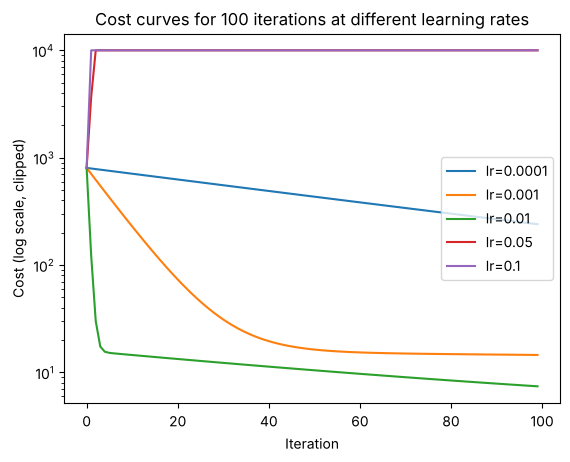

In [4]:
for lr, cs in paths.items():
    cs = np.array(cs); cs[~np.isfinite(cs)] = np.nan
    plt.plot(np.clip(cs, 0, 1e4), label=f'lr={lr}')
plt.yscale('log'); plt.xlabel('Iteration'); plt.ylabel('Cost (log scale, clipped)'); plt.legend()
plt.title('Cost curves for 100 iterations at different learning rates'); plt.show()

## Observations
* Gradient descent (lr 0.01, 1000 iterations) reached m = 3.912, c = 7.405, almost identical to closed-form OLS (3.908, 7.430). The true values were 4 and 7.
* **Iterations:** at lr 0.01 the cost fell from 14.66 (10 iterations) to 7.43 (100) to 3.23 (1000).
* **Learning rate:** 0.0001 was far too slow (cost still 14.54 after 1000 iterations); 0.001 and 0.01 improved steadily; 0.05 and 0.1 **diverged**, because each step overshot the minimum and the error grew.
* The best setting is the largest learning rate that still decreases the cost smoothly.